# 01 - Data overview

Cohort composition of the public MOSA cell line data, the EMT score used as biological factor, and the simulated technical factor (pseudo-sources) with its confounding with tissue.

In [1]:
# parameters
DATA_DIR = "data/processed"
SIMULATIONS = ["sim_c00", "sim_c05", "sim_c09"]

In [2]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from mosa_disentangle import plotting
from mosa_disentangle.data import read_dataset
from mosa_disentangle.training import block_columns

sns.set_context("paper")
plt.rcParams["figure.dpi"] = 110

In [3]:
cell_lines = read_dataset(Path(DATA_DIR) / "cell_lines.h5mu")
obs = cell_lines.metadata
coverage = pd.DataFrame(
    {view: mask.any(axis=1) for view, mask in cell_lines.masks.items()}, index=obs.index
)
print(f"{cell_lines.n_samples} cell lines")
print({v: x.shape[1] for v, x in cell_lines.views.items()})
coverage.sum().rename("samples with the view").to_frame().T

1231 cell lines
{'copynumber': 777, 'crisprcas9': 3000, 'drugresponse': 810, 'metabolomics': 225, 'methylation': 5000, 'proteomics': 4000, 'transcriptomics': 5000}


,copynumber,crisprcas9,drugresponse,metabolomics,methylation,proteomics,transcriptomics
samples with the view,1176,537,995,857,909,949,1062


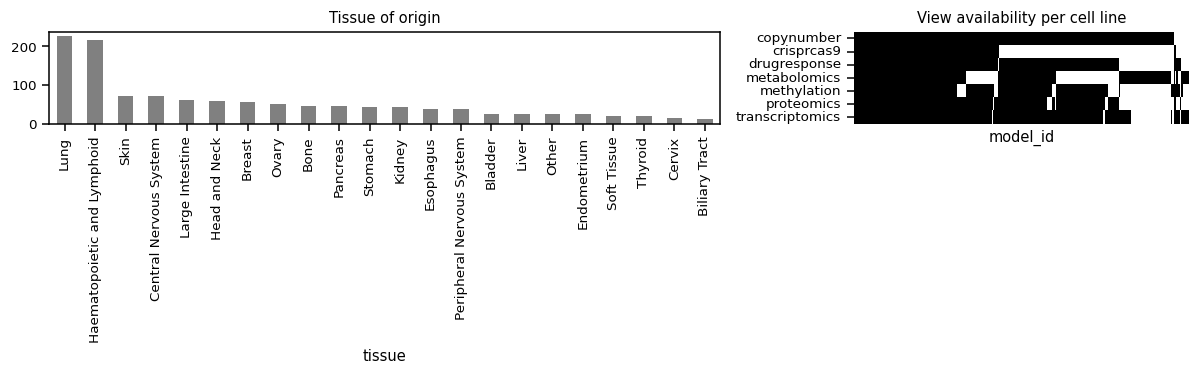

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), gridspec_kw={"width_ratios": [2, 1]})
obs["tissue"].value_counts().plot.bar(ax=axes[0], color="grey")
axes[0].set_title("Tissue of origin")
sns.heatmap(coverage.sort_values(list(coverage.columns), ascending=False).T.astype(int),
            cbar=False, ax=axes[1], xticklabels=False, cmap="Greys")
axes[1].set_title("View availability per cell line")
plt.tight_layout()

## EMT score

The transcriptomic EMT score is the mean z-score of mesenchymal markers minus epithelial markers. It is compared with the EMT score published with the Sanger proteomics cohort (Gonçalves et al., Cancer Cell 2022). Haematopoietic lines are not epithelial, so EMT is partly confounded with tissue; this is one of the reasons the biological blocks need an independence constraint rather than a pure supervised head.

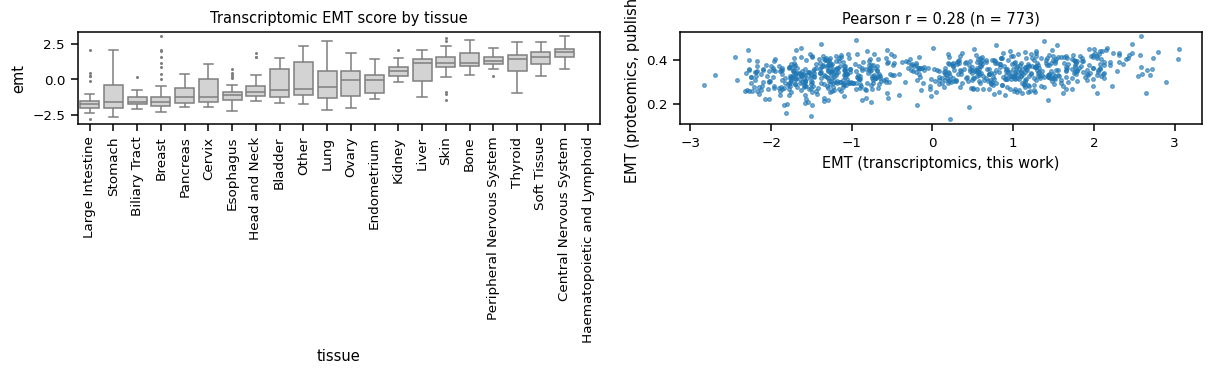

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
order = obs.groupby("tissue")["emt"].median().sort_values().index
sns.boxplot(data=obs, x="tissue", y="emt", order=order, ax=axes[0], color="lightgrey",
            fliersize=1)
axes[0].tick_params(axis="x", rotation=90)
axes[0].set_title("Transcriptomic EMT score by tissue")
both = obs.dropna(subset=["emt", "emt_proteomics"])
axes[1].scatter(both["emt"], both["emt_proteomics"], s=6, alpha=0.6)
r = np.corrcoef(both["emt"], both["emt_proteomics"])[0, 1]
axes[1].set(xlabel="EMT (transcriptomics, this work)", ylabel="EMT (proteomics, published)",
            title=f"Pearson r = {r:.2f} (n = {len(both)})")
plt.tight_layout()

## Simulated technical factor

Each cell line is assigned to a pseudo-source (`cell_line` = reference, `organoid`, `tumour`). Assignment probabilities depend on tissue with strength `confounding`; non-reference sources receive feature shifts, rescaling, a coherent programme shift and lose whole views. The first principal components show how strongly the sources separate before any correction.

,sim_c00,sim_c05,sim_c09
model_type,,,
tumour,430,436,436
organoid,416,341,301
cell_line,385,454,494


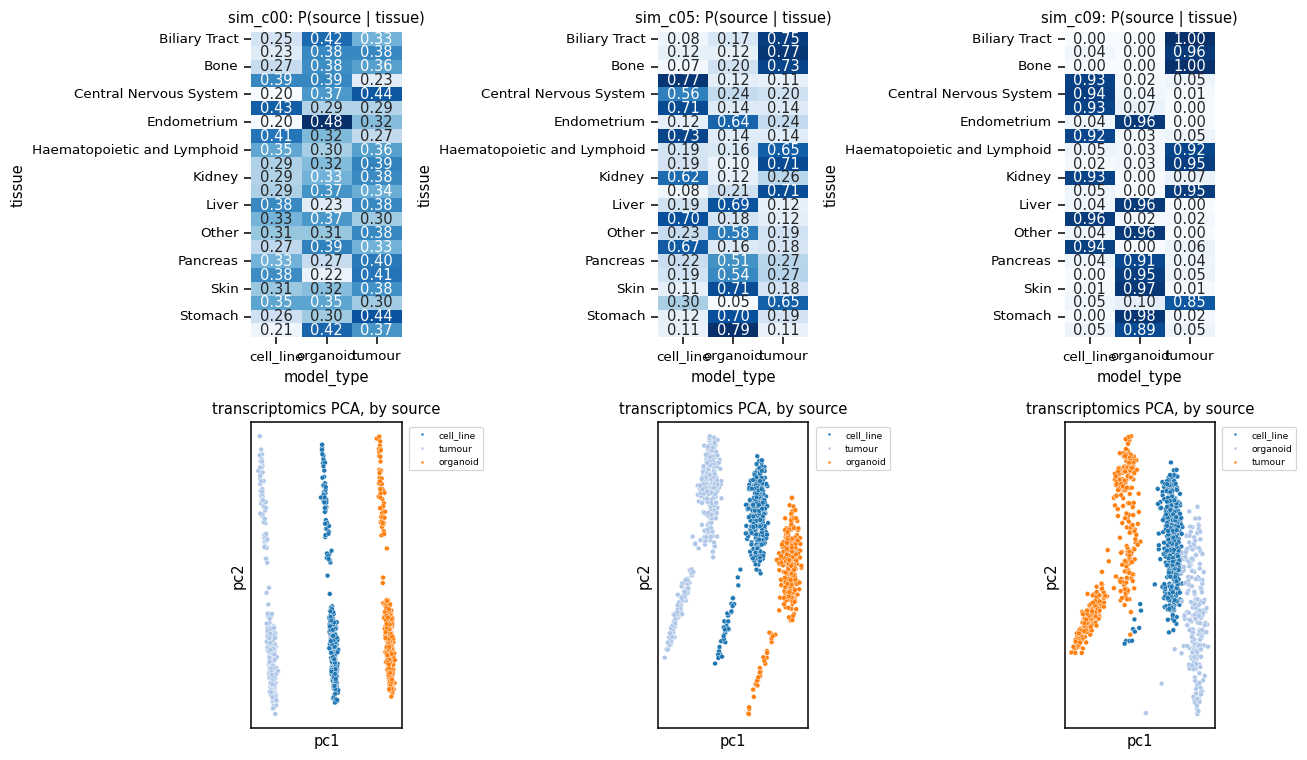

In [6]:
rows = []
fig, axes = plt.subplots(2, len(SIMULATIONS), figsize=(4 * len(SIMULATIONS), 7))
for j, sim in enumerate(SIMULATIONS):
    data = read_dataset(Path(DATA_DIR) / f"{sim}.h5mu", ["transcriptomics"])
    o = data.metadata
    table = pd.crosstab(o["tissue"], o["model_type"], normalize="index")
    sns.heatmap(table, ax=axes[0, j], cmap="Blues", cbar=False, annot=True, fmt=".2f")
    axes[0, j].set_title(f"{sim}: P(source | tissue)")
    x = data.views["transcriptomics"]
    keep = data.masks["transcriptomics"].any(axis=1)
    x = np.nan_to_num(x[keep] - np.nanmean(x[keep], axis=0))
    plotting.pca_scatter(x, o.loc[keep, "model_type"], ax=axes[1, j],
                         title="transcriptomics PCA, by source")
    rows.append(o["model_type"].value_counts().rename(sim))
plt.tight_layout()
pd.concat(rows, axis=1)